# <a id='toc1_'></a>[Tempo de chegada e desvio de feixe](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Coleta de Logs](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Por fim, vamos aplicar todas as funções que montamos para analisar qual foi a interferência real causada por um terremoto e armazenar os dados obtidos em arquivos para podermos utilizar posteriormente.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

### Tempo de chegada

Vamos considerar um dos terremotos do Panamá

In [13]:
from obspy.clients.fdsn import Client
import obspy.core.utcdatetime as utc
from module import analise_catalog

catalog = "USP"
client = Client(catalog)
events = client.get_events(
    starttime=utc.UTCDateTime("2026-10-09T00:00:00.000000Z"),
    endtime=utc.UTCDateTime("2026-10-09T23:59:00.000000Z"),
    minmagnitude=5.0,
)

event_data, time_data = analise_catalog(events, catalog, plotting=False)

In [14]:
event_data

,event_id,latitude,longitude,epicenter_distance,depth,magnitude,magnitude_type,Source,origin_time,receptor_latitude,receptor_longitude
0,Panama2026-10-09T23:12:38.857356Z,7.033004,-80.011162,43.930976,0.000000,5.411903,mb,USP,2026-10-09T23:12:38.857356Z,-22.807606,-47.052526
1,Panama2026-10-09T20:25:39.395890Z,7.671206,-81.304634,45.301436,10.000000,6.298313,mb,USP,2026-10-09T20:25:39.395890Z,-22.807606,-47.052526
2,Panama2026-10-09T20:21:41.592678Z,7.145816,-80.153854,44.111292,12.480278,5.118514,mb,USP,2026-10-09T20:21:41.592678Z,-22.807606,-47.052526
3,Panama2026-10-09T19:48:56.323765Z,7.530637,-81.143005,45.088416,4.654874,5.288268,mb,USP,2026-10-09T19:48:56.323765Z,-22.807606,-47.052526
4,South of Panama2026-10-09T19:46:01.019697Z,7.275383,-79.672798,43.857442,10.000000,5.149563,mb,USP,2026-10-09T19:46:01.019697Z,-22.807606,-47.052526
5,Panama2026-10-09T18:37:46.196386Z,7.352776,-80.436165,44.456794,10.000000,6.049727,mb,USP,2026-10-09T18:37:46.196386Z,-22.807606,-47.052526
6,Panama2026-10-09T18:22:16.278310Z,7.487480,-80.217308,44.393116,10.000000,5.246443,mb,USP,2026-10-09T18:22:16.278310Z,-22.807606,-47.052526
7,Panama2026-10-09T17:56:07.118061Z,7.194002,-81.318901,44.986691,12.600000,7.669380,mB,USP,2026-10-09T17:56:07.118061Z,-22.807606,-47.052526
8,Chile-Bolivia Border Region2026-10-09T10:22:08...,-20.339478,-68.578102,20.150962,10.000000,5.299287,mb,USP,2026-10-09T10:22:08.548996Z,-22.807606,-47.052526


In [15]:
time_data

,event_id,phase,takeoff_angle,frequency,incidente_angle,ray_parameter,travel_time,arrival_time,model_used
258,Chile-Bolivia Border Region2026-10-09T10:22:08...,P,34.6444,Unknown,34.58228,623.467324,274.319728,2026-10-09T10:26:42.868724Z,iasp91
259,Chile-Bolivia Border Region2026-10-09T10:22:08...,P,38.068464,Unknown,37.998062,676.243000,276.183879,2026-10-09T10:26:44.732875Z,iasp91
260,Chile-Bolivia Border Region2026-10-09T10:22:08...,P,36.977671,Unknown,36.909988,659.683674,276.356567,2026-10-09T10:26:44.905563Z,iasp91
261,Chile-Bolivia Border Region2026-10-09T10:22:08...,pP,145.315626,Unknown,34.622162,624.096672,277.156988,2026-10-09T10:26:45.705984Z,iasp91
262,Chile-Bolivia Border Region2026-10-09T10:22:08...,sP,160.756828,Unknown,34.612385,623.942414,278.548746,2026-10-09T10:26:47.097742Z,iasp91
...,...,...,...,...,...,...,...,...,...
22,Panama2026-10-09T23:12:38.857356Z,PKIKKIKS,2.772567,Unknown,1.60576,53.133635,2104.439480,2026-10-09T23:47:43.296836Z,iasp91
23,Panama2026-10-09T23:12:38.857356Z,SKIKKIKS,1.529767,Unknown,1.529767,50.619678,2317.573030,2026-10-09T23:51:16.430386Z,iasp91
24,Panama2026-10-09T23:12:38.857356Z,PKIKPPKIKP,3.696549,Unknown,3.696549,70.819388,2396.135152,2026-10-09T23:52:34.992508Z,iasp91
25,Panama2026-10-09T23:12:38.857356Z,PKPPKP,13.05596,Unknown,13.05596,248.142318,2463.396072,2026-10-09T23:53:42.253428Z,iasp91


Agora, vamos buscar os dados do intervalo de tempo próximo ao previsto pelo modelo. Vamos adicionar um acréscimo de uma hora antes e depois para garantir que conseguimos toda a informação necessária.

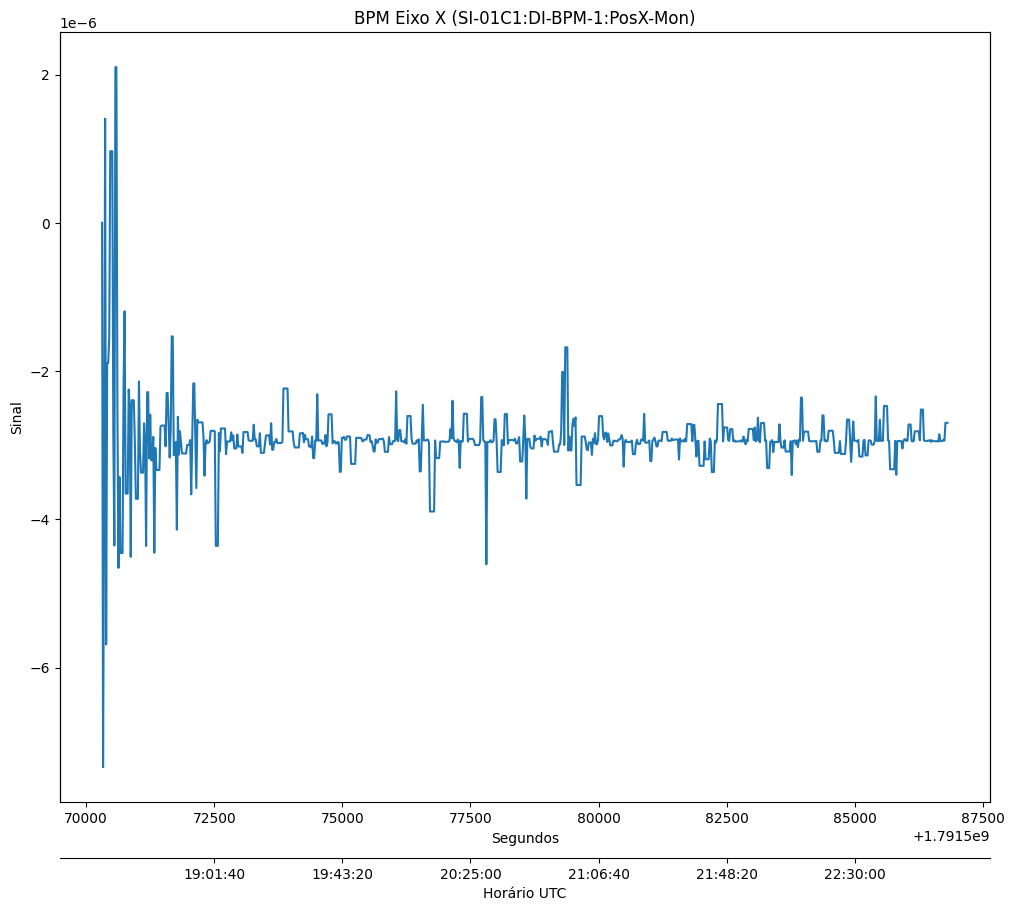

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timezone

df = pd.read_excel("sismic_data/34292.xlsx", sheet_name="SX")

# Converter segundos Unix para datetime UTC
tempo_utc = pd.to_datetime(df["secs"], unit="s", utc=True)

fig, ax = plt.subplots(figsize=(12, 10))

ax.plot(df["secs"][1:], df["val"][1:])
# ax.set_ylim(-20000, 20000)

ax.set_xlabel("Segundos")
ax.set_ylabel("Sinal")
ax.set_title("BPM Eixo X (SI-01C1:DI-BPM-1:PosX-Mon)")

# Eixo de baixo mostrando UTC
ax_utc = ax.twiny()
ax_utc.set_xlim(ax.get_xlim())

# Escolher os mesmos pontos do eixo principal
ticks = ax.get_xticks()
ticks = [t for t in ticks if df["secs"].min() <= t <= df["secs"].max()]

ax_utc.set_xticks(ticks)

ax_utc.set_xticklabels(
    [
        datetime.fromtimestamp(t, tz=timezone.utc).strftime("%H:%M:%S")
        for t in ticks
    ]
)

ax_utc.xaxis.set_ticks_position("bottom")
ax_utc.xaxis.set_label_position("bottom")

# Empurrar o eixo UTC para baixo
ax_utc.spines["bottom"].set_position(("outward", 40))
ax_utc.spines["top"].set_visible(False)

ax_utc.set_xlabel("Horário UTC")

plt.show()

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Ex non pariatur in qui amet ullamco cupidatat exercitation id commodo culpa dolore occaecat. Aute id qui excepteur voluptate et nulla. Do deserunt cupidatat minim in Lorem cupidatat consectetur cupidatat deserunt aliqua incididunt. Lorem eiusmod tempor ad ipsum minim irure. Nisi exercitation occaecat est consequat Lorem fugiat excepteur ad consectetur. Reprehenderit magna ea minim laborum adipisicing minim ipsum ut eiusmod cupidatat sit cillum reprehenderit. Pariatur elit ex aliqua laboris ea.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. EKSTRÖM, Göran. *GDM52: Seismic data processing*. [S. l.]: Columbia University, [s. d.]. Disponível em: https://www.ldeo.columbia.edu/~ekstrom/Projects/SWP/GDM52.html. Acesso em: 6 nov. 2026.